In [7]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sb
from sklearn import metrics, neighbors

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
training_path = "/content/drive/MyDrive/Colab Notebooks/customer_train.csv" # sesuaikan dengan struktur file di GDrive masing-masing
test_path = "/content/drive/MyDrive/Colab Notebooks/customer_test.csv"

df_customer_train = pd.read_csv(training_path)
df_customer_test = pd.read_csv(test_path)

In [10]:
df_customer_train.head()

,customer_id,country,gender,membership_tier,preferred_category,preferred_device,preferred_payment_method,acquisition_channel,age,total_orders,...,reviews_given,avg_review_score,returns_made,wishlist_items,newsletter_subscribed,customer_tenure_days,orders_per_year,reviews_per_order,returns_per_order,churned
0,C02470,United States,Female,Free,Books,Desktop,Credit Card,Organic Search,35,1,...,0,4.6,0,7,1,1023,0.357038,0.000000,0.000000,0
1,C01365,South Korea,Male,Free,Home & Kitchen,Desktop,Credit Card,Social Media,30,60,...,8,4.6,4,11,1,215,101.930233,0.133333,0.066667,0
2,C05213,Brazil,Female,Silver,Health & Wellness,Desktop,Credit Card,Social Media,33,13,...,3,4.3,1,1,0,1596,2.975094,0.230769,0.076923,0
3,C02126,India,Female,Free,Home & Kitchen,Mobile,Debit Card,Direct,39,26,...,3,4.0,3,0,0,1993,4.764927,0.115385,0.115385,0
4,C04709,United States,Female,Silver,Toys & Games,Mobile,Debit Card,Organic Search,50,16,...,3,4.7,0,0,0,571,10.234676,0.187500,0.000000,0


<function matplotlib.pyplot.show(close=None, block=None)>

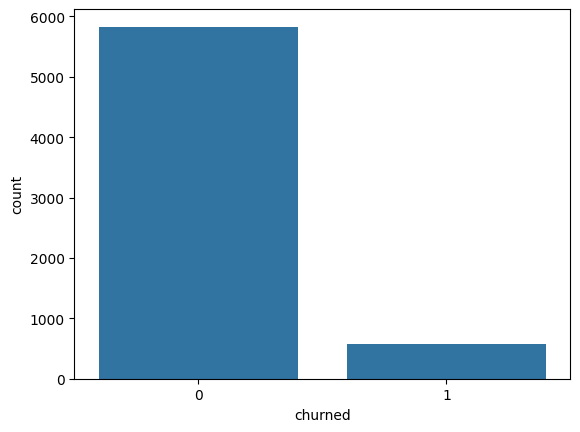

In [12]:
sb.countplot(x="churned", data=df_customer_train)
plt.show

In [13]:
df_customer_train['churned'].value_counts()

,count
churned,
0,5828
1,572


In [14]:
!pip install imblearn

In [16]:
df_customer_train['country'].value_counts()

,count
country,
United States,2018
United Kingdom,653
India,569
Germany,495
France,390
Canada,319
Brazil,303
Australia,253
Mexico,229


In [17]:
df_customer_train.loc[df_customer_train['country']=='United States']['churned'].value_counts()

,count
churned,
0,1827
1,191


In [18]:
df_customer_train.loc[df_customer_train['country']=='United Kingdom']['churned'].value_counts()

,count
churned,
0,601
1,52


In [15]:
df_customer_train.loc[(df_customer_train['churned']==0)&(df_customer_train['country']=='United States')].value_counts()

,,,,,,,,,,,,,,,,,,,,,,,count
customer_id,country,gender,membership_tier,preferred_category,preferred_device,preferred_payment_method,acquisition_channel,age,total_orders,total_spend_usd,avg_order_value_usd,days_since_last_purchase,reviews_given,avg_review_score,returns_made,wishlist_items,newsletter_subscribed,customer_tenure_days,orders_per_year,reviews_per_order,returns_per_order,churned,
C00001,United States,Male,Free,Food & Grocery,Mobile,Debit Card,Social Media,40,4,286.63,63.78,49,1,4.5,0,12,0,2631,0.555302,0.250000,0.000000,0,1
C00002,United States,Female,Free,Toys & Games,Mobile,Debit Card,Organic Search,20,11,1245.18,107.32,126,2,2.6,1,1,0,28,143.491071,0.181818,0.090909,0,1
C00003,United States,Female,Gold,Home & Kitchen,Mobile,PayPal,Referral,43,4,195.37,42.74,0,0,4.8,0,0,1,52,28.096154,0.000000,0.000000,0,1
C00009,United States,Male,Free,Clothing & Apparel,Mobile,Credit Card,Organic Search,47,49,4320.40,88.62,4,16,3.9,4,4,1,14,1278.375000,0.326531,0.081633,0,1
C00011,United States,Female,Silver,Home & Kitchen,Mobile,UPI / Digital Wallet,Organic Search,64,27,253.72,9.18,54,10,4.3,3,1,1,162,60.875000,0.370370,0.111111,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
C07987,United States,Female,Free,Toys & Games,Mobile,PayPal,Social Media,22,9,894.63,115.01,9,3,3.6,0,3,1,45,73.050000,0.333333,0.000000,0,1
C07990,United States,Female,Free,Home & Kitchen,Desktop,Credit Card,Organic Search,18,4,271.05,63.91,219,0,4.0,0,0,1,51,28.647059,0.000000,0.000000,0,1
C07991,United States,Female,Silver,Books,Mobile,Debit Card,Social Media,55,48,1572.76,37.25,25,3,4.1,3,10,1,641,27.351014,0.062500,0.062500,0,1
